# Lab 01 · 시계열 예측: 기준선, 백테스트, 그리고 파운데이션 모델

**이 실습이 다루는 자료** ([필독 목록](../READING_LIST.md) · [실습 가이드](../PRACTICE.md))

| 절 | 직접 확인할 것 | 관련 자료 |
|---|---|---|
| 1 | 시계열은 무작위로 나누면 안 된다 → 시간 순서 백테스트 | *Forecasting: Principles and Practice* (FPP3) |
| 2 | 가장 먼저 만들 기준선과 MASE | Hyndman & Koehler (2006) *Another look at measures of forecast accuracy* |
| 3 | 고전 통계 모델(ETS) | Makridakis et al. (2018) *Statistical and ML forecasting methods* |
| 4 | 과거 값만 보는 선형 모델 | Zeng et al. (2022) *Are Transformers Effective for Time Series Forecasting?* |
| 5 | lag 특성 + 미래에 알 수 있는 공변량을 쓰는 LightGBM | *M5 accuracy competition* (2022) |
| 6 | 학습 없이 예측하는 파운데이션 모델 (zero-shot) | *Chronos* (2024), *Chronos-2* (2025) |
| 7 | 여러 구간에서 비교하고, 예측 구간의 포함률 확인 | *fev-bench* (2025), *GIFT-Eval* (2024) |

**소요 시간**: 90분 · **패키지**: numpy, pandas, matplotlib, scikit-learn, statsmodels, lightgbm · 6절만 추가로 `pip install chronos-forecasting` (없으면 6절은 자동으로 건너뜁니다)

> 데이터는 직접 만든 **합성 일별 수요**입니다(추세 × 요일 효과 × 연간 계절성 × 프로모션 효과 × 며칠씩 이어지는 잡음). 어떤 성분이 들어 있는지 알고 있으므로 각 모델이 무엇을 잡고 무엇을 놓치는지 해석할 수 있습니다.

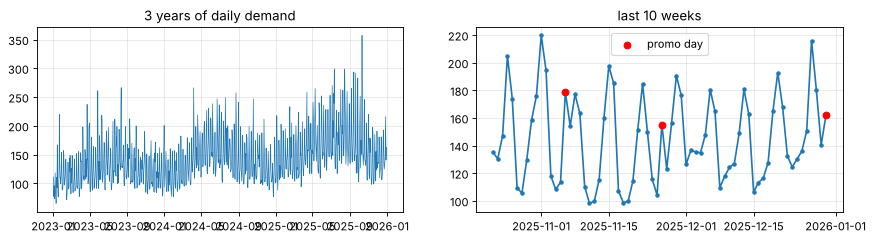

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings("ignore")
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.figsize": (10, 3), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

dates = pd.date_range("2023-01-01", periods=3 * 365, freq="D"); n = len(dates); t = np.arange(n)
dow = dates.dayofweek.to_numpy()
weekly = np.array([0.90, 0.85, 0.90, 1.00, 1.20, 1.50, 1.30])[dow]          # 월~일 요일 효과
yearly = 1 + 0.15 * np.sin(2 * np.pi * (t - 80) / 365.25)                   # 연간 계절성
trend = 100 + 0.05 * t                                                      # 완만한 성장
promo = (rng.random(n) < 0.08).astype(int)                                  # 프로모션 날(미리 계획되어 미래 값도 안다)
shock = rng.normal(0, 0.07, n); noise = np.zeros(n)
for i in range(1, n): noise[i] = 0.7 * noise[i - 1] + shock[i]                # 며칠씩 이어지는 변동(자기상관이 있는 잡음)
y = trend * weekly * yearly * (1 + 0.35 * promo) * np.exp(noise)
df = pd.DataFrame({"date": dates, "y": y, "promo": promo, "dow": dow})

fig, axes = plt.subplots(1, 2, figsize=(13, 3))
axes[0].plot(df.date, df.y, lw=0.6); axes[0].set_title("3 years of daily demand")
last = df.tail(70); axes[1].plot(last.date, last.y, "o-", ms=3); axes[1].scatter(last.date[last.promo == 1], last.y[last.promo == 1], c="r", zorder=3, label="promo day")
axes[1].set_title("last 10 weeks"); axes[1].legend(); plt.show()

## 1. 평가 설계: 시간 순서 백테스트

예측 과제: **매번 다음 14일을 예측**한다. 평가는 마지막 16주를 14일짜리 구간 8개로 나누어, 각 구간 직전까지의 데이터만 써서 예측합니다(rolling-origin).

✍️ **예측**: 행을 무작위로 섞어 train/test를 나누면 왜 안 될까요? (힌트: 2024-03-15를 예측하는 데 2024-03-16의 값을 쓰게 된다면?)

In [2]:
H, N_FOLDS, SEASON = 14, 8, 7
cutoffs = [n - H * k for k in range(N_FOLDS, 0, -1)]                          # 각 구간의 시작 위치

def mase(y_true, y_pred, y_insample, m=SEASON):
    """예측 MAE를 '학습 구간에서 계절성 나이브가 낸 MAE'로 나눈 값. 1보다 작으면 그 기준선보다 좋다."""
    return np.mean(np.abs(y_true - y_pred)) / np.mean(np.abs(y_insample[m:] - y_insample[:-m]))

def backtest(forecast_fn):
    """forecast_fn(train_df, future_df) → 길이 H의 예측. future_df에는 미리 알 수 있는 열(date, promo, dow)만 준다."""
    scores, preds = [], []
    for c in cutoffs:
        train_df, test_df = df.iloc[:c], df.iloc[c:c + H]
        pred = np.asarray(forecast_fn(train_df, test_df[["date", "promo", "dow"]]))
        scores.append(mase(test_df.y.to_numpy(), pred, train_df.y.to_numpy())); preds.append(pred)
    return np.array(scores), preds

results, all_preds = {}, {}

## 2. 기준선 (Hyndman & Koehler, 2006)

- **naive**: 마지막 관측값이 계속된다
- **seasonal naive**: 지난주 같은 요일 값이 반복된다

**MASE**는 오차를 "학습 구간에서 seasonal naive가 낸 평균 오차"로 나눈 값입니다. 단위가 없어 시리즈끼리 비교할 수 있고, MAPE처럼 실제값이 0 근처일 때 폭발하지 않습니다.

✍️ **예측**: naive와 seasonal naive의 MASE는 각각 1보다 클까요, 작을까요?

In [3]:
def naive(train_df, future): return np.repeat(train_df.y.iloc[-1], H)
def seasonal_naive(train_df, future): return np.tile(train_df.y.to_numpy()[-SEASON:], H // SEASON + 1)[:H]

for name, fn in {"naive": naive, "seasonal naive": seasonal_naive}.items():
    results[name], all_preds[name] = backtest(fn)
    print(f"{name:15s} MASE 평균 = {results[name].mean():.3f}   (구간별: {results[name].round(2)})")

naive           MASE 평균 = 1.884   (구간별: [2.38 2.08 2.03 1.57 1.79 2.16 1.04 2.01])
seasonal naive  MASE 평균 = 0.990   (구간별: [0.93 1.25 1.2  1.17 1.04 0.75 0.74 0.84])


요일 효과가 강한 데이터에서 naive는 매우 나쁩니다. **계절성 나이브를 이기지 못하는 모델은 쓸 이유가 없습니다.** 논문 표에서 이 기준선이 빠져 있다면 의심하세요.

## 3. 고전 통계 모델: 지수평활(ETS / Holt-Winters)

수준·추세·계절성을 각각 지수 가중 평균으로 갱신하는 모델입니다. M 대회에서 수십 년간 강한 기준선이었습니다.

In [4]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
def ets(train_df, future):
    model = ExponentialSmoothing(train_df.y.to_numpy(), trend="add", seasonal="mul", seasonal_periods=SEASON).fit()
    return model.forecast(H)
results["ETS"], all_preds["ETS"] = backtest(ets)
print(f"ETS MASE 평균 = {results['ETS'].mean():.3f}   (구간별: {results['ETS'].round(2)})")

ETS MASE 평균 = 1.014   (구간별: [0.97 1.46 1.24 1.36 0.89 0.56 0.89 0.74])


## 4. 과거 값만 보는 선형 모델 (Zeng et al., 2022)

"최근 28일 값 → 다음 14일 값"을 선형 회귀 하나로 학습합니다. 이 논문은 이런 단순한 선형 모델이 당시의 여러 시계열 Transformer를 이겼다고 보고해, 비교 실험을 다시 보게 만들었습니다.

In [5]:
from sklearn.linear_model import Ridge
LOOKBACK = 28
def linear_on_lags(train_df, future):
    v = train_df.y.to_numpy()
    X = np.lib.stride_tricks.sliding_window_view(v, LOOKBACK + H)             # 모든 (입력 28일, 출력 14일) 창
    Xw, Yw = X[:, :LOOKBACK], X[:, LOOKBACK:]
    mu = Xw.mean(axis=1, keepdims=True)                                       # 창마다 평균으로 나눠 수준 변화에 견디게
    model = Ridge(alpha=1.0).fit(Xw / mu, Yw / mu)
    last = v[-LOOKBACK:]
    return model.predict((last / last.mean())[None])[0] * last.mean()
results["linear on lags"], all_preds["linear on lags"] = backtest(linear_on_lags)
print(f"linear on lags MASE 평균 = {results['linear on lags'].mean():.3f}")

linear on lags MASE 평균 = 1.100


## 5. LightGBM + lag 특성 + 미래에 아는 공변량 (M5 대회의 교훈)

지금까지의 모델은 **프로모션 계획을 모릅니다.** 트리 모델에는 달력·프로모션 같은 "미래에도 아는 정보"를 특성으로 넣을 수 있습니다.

주의할 점: 14일 뒤를 예측할 때 쓸 수 있는 과거 값은 **14일 이상 전의 값**뿐입니다. `lag 1`(어제 값)을 특성으로 쓰면 평가에서는 정답을 훔쳐보게 됩니다(누수). 그래서 lag은 14, 21, 28만 씁니다.

✍️ **예측**: 프로모션 정보를 아는 LightGBM은 ETS보다 얼마나 좋아질까요?

In [6]:
import lightgbm as lgb
def make_features(frame, min_lag=H):
    f = pd.DataFrame(index=frame.index)
    for lag in [min_lag, min_lag + 7, min_lag + 14]: f[f"lag{lag}"] = frame.y.shift(lag)
    f["roll_mean"] = frame.y.shift(min_lag).rolling(28).mean()                # 14일 전까지의 최근 4주 평균
    f["dow"], f["promo"] = frame.dow, frame.promo
    f["doy_sin"] = np.sin(2 * np.pi * frame.date.dt.dayofyear / 365.25); f["doy_cos"] = np.cos(2 * np.pi * frame.date.dt.dayofyear / 365.25)
    return f

def lgbm(train_df, future, min_lag=H):
    full = pd.concat([train_df, future.assign(y=np.nan)], ignore_index=True)  # 미래 구간의 y는 비워 둔다
    feats = make_features(full, min_lag)
    is_train = full.y.notna() & feats.notna().all(axis=1)
    model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=10, verbose=-1, random_state=0)
    model.fit(feats[is_train], full.y[is_train] / feats.roll_mean[is_train])  # 수준(최근 평균) 대비 비율을 예측
    fut = feats.iloc[len(train_df):]
    return model.predict(fut) * fut.roll_mean.to_numpy()
results["LightGBM (lags + promo)"], all_preds["LightGBM (lags + promo)"] = backtest(lgbm)
print(f"LightGBM MASE 평균 = {results['LightGBM (lags + promo)'].mean():.3f}")

LightGBM MASE 평균 = 0.869


## 6. 파운데이션 모델: 학습 없이 예측하기 (Chronos-2)

시계열 파운데이션 모델은 수많은 시계열로 사전학습되어, **우리 데이터로 학습하지 않고**(zero-shot) 과거 값만 넣으면 예측을 냅니다. Chronos-2는 프로모션 같은 공변량도 입력으로 받습니다. 가중치가 공개된 작은 버전(`autogluon/chronos-2-small`, 약 2,800만 파라미터)을 CPU로 돌립니다.

✍️ **예측**: 이 데이터를 한 번도 본 적 없는 모델이, 이 데이터로 학습한 LightGBM과 비슷한 수준이 될 수 있을까요?

In [7]:
try:
    from chronos import Chronos2Pipeline
    pipeline = Chronos2Pipeline.from_pretrained("autogluon/chronos-2-small", device_map="cpu")
    QUANTILES = [0.1, 0.5, 0.9]; chronos_quantiles = []

    def chronos2(train_df, future, use_promo=True):
        context = train_df[["date", "y"] + (["promo"] if use_promo else [])].rename(columns={"date": "timestamp", "y": "target"}).assign(id="shop")
        future_df = future[["date", "promo"]].rename(columns={"date": "timestamp"}).assign(id="shop") if use_promo else None
        pred = pipeline.predict_df(context, future_df=future_df, prediction_length=H, quantile_levels=QUANTILES,
                                   id_column="id", timestamp_column="timestamp", target="target")
        if use_promo: chronos_quantiles.append(pred[["0.1", "0.9"]].to_numpy())
        return pred["0.5"].to_numpy()

    results["Chronos-2 small (zero-shot)"], all_preds["Chronos-2 small (zero-shot)"] = backtest(lambda a, b: chronos2(a, b, use_promo=False))
    results["Chronos-2 small (zero-shot + promo)"], all_preds["Chronos-2 small (zero-shot + promo)"] = backtest(chronos2)
    HAVE_CHRONOS = True
except ImportError:
    HAVE_CHRONOS = False
    print("chronos-forecasting 이 설치되어 있지 않아 6절을 건너뜁니다.  →  pip install chronos-forecasting")

## 7. 결과 비교: 평균만 보지 말고 구간별 흔들림도

✍️ **예측**: 8개 구간 **모두에서** 1등인 모델이 있을까요?

                                     MASE_mean  MASE_std  best_folds
Chronos-2 small (zero-shot + promo)      0.723     0.165         3.0
LightGBM (lags + promo)                  0.869     0.235         1.0
Chronos-2 small (zero-shot)              0.883     0.331         2.0
seasonal naive                           0.990     0.203         0.0
ETS                                      1.014     0.314         2.0
linear on lags                           1.100     0.426         0.0
naive                                    1.884     0.415         0.0


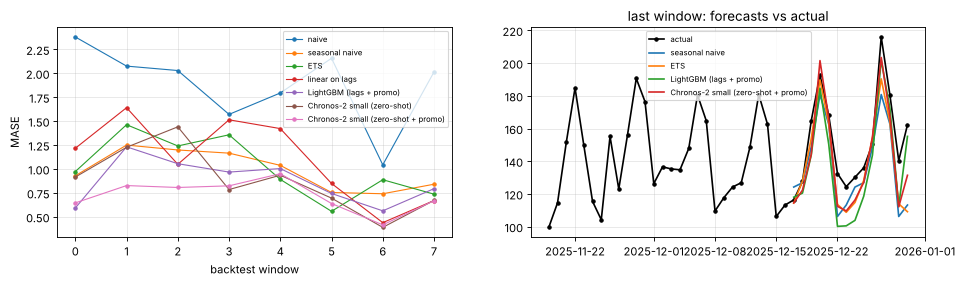

In [8]:
table = pd.DataFrame({name: dict(MASE_mean=s.mean(), MASE_std=s.std(ddof=1), best_folds=0) for name, s in results.items()}).T
per_fold = pd.DataFrame(results)
for winner in per_fold.idxmin(axis=1): table.loc[winner, "best_folds"] += 1
print(table.sort_values("MASE_mean").round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
per_fold.plot(ax=axes[0], marker="o", ms=3, lw=1); axes[0].set_xlabel("backtest window"); axes[0].set_ylabel("MASE"); axes[0].legend(fontsize=7)
c = cutoffs[-1]; axes[1].plot(df.date.iloc[c - 28:c + H], df.y.iloc[c - 28:c + H], "k.-", label="actual")
for name in ["seasonal naive", "ETS", "LightGBM (lags + promo)"] + (["Chronos-2 small (zero-shot + promo)"] if HAVE_CHRONOS else []):
    axes[1].plot(df.date.iloc[c:c + H], all_preds[name][-1], label=name)
axes[1].set_title("last window: forecasts vs actual"); axes[1].legend(fontsize=7); plt.show()

표와 그림에서 확인할 것
- **프로모션을 아는 모델**(공변량을 넣은 Chronos-2, LightGBM)이 위쪽에 있습니다. 과거 값만으로는 "다음 주 화요일에 행사가 있다"는 사실을 알 수 없습니다. M5 대회에서 가격·행사 정보를 쓴 LightGBM 계열이 상위를 차지한 것과 같은 이유입니다.
- **학습을 전혀 하지 않은** 파운데이션 모델이, 이 데이터로 학습한 LightGBM과 비슷하거나 더 좋습니다. 다만 이것은 깨끗한 합성 데이터 한 개에서 나온 결과입니다. 벤치마크 논문(fev-bench, GIFT-Eval)이 수십~수백 개 과제에서 **신뢰구간과 함께** 비교하는 이유를 생각해 보세요.
- **ETS와 선형 모델은 seasonal naive를 이기지 못했습니다.** 더 복잡하다고 기준선을 이기는 것은 아닙니다. "단순한 선형 모델이 Transformer를 이긴다"(Zeng et al.)도, "통계 모델이 ML을 이긴다"(Makridakis et al.)도 **그 논문의 데이터와 설정 안에서** 성립한 결과라는 점을 기억하세요.
- 구간별 MASE는 크게 흔들리고, 구간마다 1등이 바뀝니다(`best_folds` 열). **test 구간 하나로 모델 순위를 정하면 안 됩니다.**

### 예측 구간이 믿을 만한가

점 예측만큼 중요한 것이 불확실성입니다. Chronos-2가 낸 10%~90% 분위수 구간(80% 구간)에 실제값이 80% 들어가는지 확인합니다.

In [9]:
if HAVE_CHRONOS:
    inside = []
    for c, q in zip(cutoffs, chronos_quantiles):
        actual = df.y.iloc[c:c + H].to_numpy(); inside.append((actual >= q[:, 0]) & (actual <= q[:, 1]))
    print(f"80% 예측 구간의 실제 포함률 = {np.mean(inside):.2f}   (점 {np.size(inside)}개 기준)")

80% 예측 구간의 실제 포함률 = 0.78   (점 112개 기준)


이 실행에서는 포함률이 명목값 80%에 가깝습니다(점이 112개뿐이라 몇 %p의 오차는 있습니다). 포함률이 80%보다 훨씬 낮으면 모델이 **과신**(구간이 너무 좁음), 훨씬 높으면 구간이 쓸데없이 넓은 것입니다. 재고·인력 계획처럼 "최악의 경우"를 대비하는 문제에서는 점 예측의 정확도보다 이 보정(calibration)이 더 중요할 수 있습니다.

---
## 직접 해보기

1. **(누수 만들기)** `lgbm(..., min_lag=1)` 로 바꿔 백테스트하면 MASE가 어떻게 되나요? 왜 이 숫자를 믿으면 안 되는지, 실제 배포에서는 어떤 일이 생기는지 설명하세요.
2. **(MAPE의 함정)** 실제값 `[100, 2, 50]`, 예측 `[90, 4, 55]` 의 MAPE와 MAE를 계산하세요. 어느 표본이 MAPE를 지배하나요?
3. **(이상 탐지)** 아래 코드가 수요에 이상값 5개를 심어 둡니다. "지난 4주 같은 요일의 중앙값"과의 차이를 로버스트 z-점수(MAD 기준)로 만들어 이상값을 찾아보세요. 프로모션 날은 어떻게 처리해야 할까요?

In [10]:
df_anom = df.copy(); anomaly_idx = rng.choice(np.arange(400, n), 5, replace=False)
df_anom.loc[anomaly_idx, "y"] *= rng.choice([0.3, 2.2], 5)
# TODO 1: min_lag=1 로 백테스트

# TODO 2: MAPE vs MAE

# TODO 3: 이상값 5개 찾기

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

In [11]:
# 1. lag 1을 쓰면: 평가에서는 '어제의 실제값'이 채워져 있어 좋아 보이지만...
def lgbm_leaky(train_df, future):
    full = pd.concat([train_df, df.loc[future.index, ["date", "y", "promo", "dow"]]], ignore_index=True)   # 미래의 실제 y를 넣어 버림(누수)
    feats = make_features(full, min_lag=1); ok = feats.notna().all(axis=1); is_train = ok & (full.index < len(train_df))
    model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=10, verbose=-1, random_state=0)
    model.fit(feats[is_train], full.y[is_train] / feats.roll_mean[is_train])
    fut = feats.iloc[len(train_df):]
    return model.predict(fut) * fut.roll_mean.to_numpy()
leaky, _ = backtest(lgbm_leaky)
print(f"누수 있는 LightGBM의 MASE = {leaky.mean():.3f}   vs   올바른 LightGBM = {results['LightGBM (lags + promo)'].mean():.3f}")

누수 있는 LightGBM의 MASE = 0.602   vs   올바른 LightGBM = 0.869


In [12]:
# 2. MAPE vs MAE
actual, pred = np.array([100, 2, 50]), np.array([90, 4, 55])
ape = np.abs(actual - pred) / actual
print("표본별 절대 백분율 오차:", ape.round(2), "→ MAPE =", f"{ape.mean():.0%}", "| MAE =", np.abs(actual - pred).mean().round(2))

표본별 절대 백분율 오차: [0.1 1.  0.1] → MAPE = 40% | MAE = 5.67


In [13]:
# 3. 로버스트 z-점수로 이상값 찾기 (프로모션 효과는 먼저 제거)
s = df_anom.y / (1 + 0.35 * df_anom.promo)                                   # 여기서는 효과 크기를 안다고 가정. 실제로는 추정하거나 프로모션 날을 따로 본다
same_dow = pd.concat([s.shift(7 * k) for k in range(1, 5)], axis=1)
resid = np.log(s) - np.log(same_dow.median(axis=1))
mad = (resid - resid.median()).abs().median()
z = 0.6745 * (resid - resid.median()) / mad
found = set(z.index[z.abs() > 4])
print("심어 둔 이상값:", sorted(anomaly_idx.tolist())); print("찾은 것        :", sorted(found))
print(f"정탐 {len(found & set(anomaly_idx.tolist()))}개 / 오탐 {len(found - set(anomaly_idx.tolist()))}개")

심어 둔 이상값: [511, 754, 769, 846, 889]
찾은 것        : [23, 511, 754, 769, 846, 889]
정탐 5개 / 오탐 1개


**해석**
- 1번: 누수가 있는 버전은 훨씬 좋아 보입니다(수요의 변동이 며칠씩 이어지므로 "어제 값"이 강력한 힌트가 됩니다). 하지만 실제로 14일 뒤를 예측할 때는 "13일 뒤의 실제값"이 없습니다. 배포하면 그 특성을 채울 수 없어 성능이 무너집니다. 논문·블로그에서 "1-step-ahead" 평가와 "multi-step" 평가를 구별해서 읽어야 합니다.
- 2번: 실제값이 2인 표본 하나(오차 2)가 100% 오차로 계산되어 MAPE를 지배합니다. 간헐적 수요(0이 많은 데이터)에서 MAPE를 쓰면 안 되는 이유이며, Hyndman & Koehler가 MASE를 제안한 배경입니다.
- 3번: 프로모션처럼 **설명 가능한 급등**을 먼저 제거하지 않으면 전부 이상값으로 잡힙니다. 이상 탐지는 "무엇이 정상인가"를 먼저 모델링하는 문제입니다. 벤치마크의 라벨·평가 방식 자체에 결함이 있을 수 있다는 지적(Wu & Keogh, 2020)도 함께 읽어 보세요.

---
## 논문으로 돌아가기

| 방금 한 것 | 논문에서 확인할 곳 |
|---|---|
| 2절 MASE | Hyndman & Koehler (2006): 기존 지표들(MAPE, sMAPE 등)이 깨지는 상황 정리와 scaled error의 정의 |
| 3절 vs 5절 | Makridakis (2018): ML 방법들이 통계 방법보다 못했던 실험 설정. M5 (2022): 무엇이 달라져 ML이 이겼는가(여러 시리즈 함께 학습, 외부 변수) |
| 4절 | Zeng (2022): LTSF-Linear의 구조와, lookback 길이를 늘렸을 때 Transformer들의 성능 변화 그림. 반론인 PatchTST (2022)와 함께 |
| 6절 | Chronos (2024): 시계열을 토큰으로 바꾸는 방법(스케일링 + 양자화). Chronos-2 (2025): 공변량·다변량을 어떻게 한 모델로 처리하는가 |
| 7절 | fev-bench (2025): 왜 "승률"과 "skill score"를 신뢰구간과 함께 보고하는가 |

## 기억 점검

1. 시계열을 무작위로 분할하면 생기는 문제는? 대신 어떻게 평가하나?
2. seasonal naive 예측이란? MASE가 1보다 작다는 것은 무슨 뜻인가?
3. 14일 앞을 예측하는 모델에 lag 1 특성을 넣으면 왜 누수인가?
4. 과거 값만 쓰는 모델이 원리적으로 예측할 수 없는 것은? 무엇을 넣어야 하나?
5. 80% 예측 구간의 실제 포함률이 55%라면 무슨 뜻인가?

<details><summary>답 확인</summary>

1. 미래 값으로 과거를 예측하게 되어 성능이 과대평가된다. 시간 순서로 과거 → 미래로 나누고, 여러 시점에서 반복하는 rolling-origin 백테스트를 한다.
2. 한 계절 주기 전(지난주 같은 요일)의 값을 그대로 쓰는 예측. MASE<1이면 학습 구간에서의 seasonal naive보다 평균 오차가 작다.
3. 예측 시점에는 13일 뒤의 실제값이 존재하지 않는다. 평가 데이터에는 채워져 있어서 정답에 가까운 정보를 훔쳐보게 된다.
4. 프로모션·휴일·가격 변경처럼 과거 패턴에 없는 계획된 사건. 미래에도 알 수 있는 공변량으로 넣어야 한다.
5. 모델이 과신한다(구간이 너무 좁다). 불확실성을 과소평가하므로 재고·위험 관리에 그대로 쓰면 위험하다.
</details>